In [53]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [54]:
import numpy as np

import meep as mp
from meep import mpb

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as colors

import src as mf

# ...
import pythtb as tb

Just a bit of code to make figures more beautiful

In [55]:
mpl.rcParams.update({
    # Figure
    "figure.figsize": (7, 6),   # default figure size in inches, for one-column width
    "figure.dpi": 300,              # higher resolution

    # Font
    "font.family": "serif",         # switch to serif (journal-style)
    "font.size": 11,                # base font size
    "mathtext.fontset": "stix",     # match math to Times-like font

    # Axes
    "axes.labelsize": 11,           # axis label font size
    "axes.titlesize": 12,           # title font size
    "axes.linewidth": 1,            # thickness of axes spines

    # Ticks
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,

    # Tick length/width
    "xtick.major.size": 4,
    "xtick.major.width": 1,
    "ytick.major.size": 4,
    "ytick.major.width": 1,

    # Grid (off by default, but can be enabled)
    "grid.alpha": 0.3,
    "grid.linestyle": "--",

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False,
})

## Set-up the model for the numerical simulation

In [56]:
# INPUTS --------------------------------------------------------------------------------- #
NUM_BANDS = 2

EPSILON_INPUT_FILE = "data/kimble/epsilon.h5"

TOLERANCE = 1e-7

N_CELLS = 41 # number of unit cells in each direction

# .. define number of points per direction for the Monkhorst-Pack grid
NK = 64

# angles for the dipole moments of the quantum emitters
THETA_1 = (90) * np.pi / 180
THETA_2 = (135) * np.pi / 180

# Positions of the quantum emitters in units of the lattice constant 'a'
R0_LIST = [
    [0.00, 0.00, 0.0],
    [-1.00, 0.00, 0.0],
    [0.00, -1.00, 0.0],
    [1.00, 0.00, 0.0],
    [0.00, 1.00, 0.0],
    [-0.50, -0.50, 0.0],
    [0.50, -0.50, 0.0],
    [0.50, 0.50, 0.0],
    [-0.50, 0.50, 0.0],
    [-0.50, 0.00, 0.0],
    [0.50, 0.00, 0.0],
    [0.00, 0.50, 0.0],
    [-0.50, 0.00, 0.0],
]

# small inputs for the tight-binding model
LAT = [[1, 0], [0, 1]]
ORB = [[0, 0]]

BAND_INDEX = 0  # index of the band to consider (0-based)

# coefficients for the tight-binding model
ALPHA = 0.07755639
J1 = -0.01993698
J2 = 0.00053966

# path in the Brillouin zone for band structure calculation
K_PATH = [[0, 0], [0, 0.5], [0.5, 0.5], [0, 0]]
# define HSPs labels
K_LABEL = [r"$\Gamma$", r"X", r"M", r"$\Gamma$"]

T0 = 0 # initial time for the field snapshots
TF = 20 # final time for the field snapshots
T_STEPS = 100 # number of time steps for the field snapshots
TIME_INDEX = 45 # time index to consider for the field snapshots

# ---------------------------------------------------------------------------------------- #

# Read some data from the epsilon.h5 file
d = mf.read_epsilon_file(EPSILON_INPUT_FILE)
resolution = d["resolution"]
lattice_vecs = d["lattice vectors"]
lattice_size = d["lattice size"]

# Print summary of parameters
print("\n")
print("Number of bands      = " + str(NUM_BANDS))
print("Epsilon file used    = " + EPSILON_INPUT_FILE)
print("Resolution           = " + str(resolution))
print("Lattice size         = " + str(lattice_size))
print("Lattice vectors      = " + str(lattice_vecs))
print("Tolerance            = " + str(TOLERANCE))



Number of bands      = 2
Epsilon file used    = data/kimble/epsilon.h5
Resolution           = [64, 64, 1]
Lattice size         = [np.float64(1.0), np.float64(1.0), 0]
Lattice vectors      = [[1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]]
Tolerance            = 1e-07


## Figure 2

In [57]:
infiniteModel = tb.tb_model(2, 2, LAT, ORB)

# onsite term
infiniteModel.set_onsite([ALPHA])

# 1st nn
infiniteModel.set_hop(J1, 0, 0, [1, 0])
infiniteModel.set_hop(J1, 0, 0, [0, 1])

# 2nd nn
infiniteModel.set_hop(J2, 0, 0, [1, 1])
infiniteModel.set_hop(J2, 0, 0, [1, -1])

In [58]:
# %% Compute bands for the infinite model

### Compute bands along high-symmetry path ...

# creates a path between the HSPs defined before with 500 points between them
k_vec, k_dist, k_node = infiniteModel.k_path(K_PATH, 500, report=False)

# solve the infinite model in the considered path
evals = infiniteModel.solve_all(k_vec)

In [59]:
# compute the bands with MPB for comparison

geometry_lattice = mp.Lattice(
    size=lattice_size, basis1=lattice_vecs[0], basis2=lattice_vecs[1]
)

ms = mpb.ModeSolver(
    num_bands=NUM_BANDS,
    resolution=mp.Vector3(*resolution),
    epsilon_input_file=EPSILON_INPUT_FILE,
    tolerance=TOLERANCE,
    mesh_size=1,
    geometry_lattice=geometry_lattice,
    k_points=mf.array_to_Vector3(k_vec),
)

ms.run_te()

# all frequency bands
freqs = ms.all_freqs

Initializing eigensolver data
Computing 2 bands with 1e-07 tolerance
Working in 2 dimensions.
Grid size is 64 x 64 x 1.
Solving for 2 bands at a time.
Creating Maxwell data...
Mesh size is 1.
Lattice vectors:
     (1, 0, 0)
     (0, 1, 0)
     (0, 0, 1)
Cell volume = 1
Reciprocal lattice vectors (/ 2 pi):
     (1, -0, 0)
     (-0, 1, -0)
     (0, -0, 1)
Geometric objects:
Geometric object tree has depth 1 and 0 object nodes (vs. 0 actual objects)
read in 64x64x1 epsilon-input-file "data/kimble/epsilon.h5"
Initializing epsilon function...
Allocating fields...
Solving for band polarization: te.
Initializing fields to random numbers...
500 k-points
  Vector3<0.0, 0.0, 0.0>
  Vector3<0.0, 0.003424657534246575, 0.0>
  Vector3<0.0, 0.00684931506849315, 0.0>
  Vector3<0.0, 0.010273972602739725, 0.0>
  Vector3<0.0, 0.0136986301369863, 0.0>
  Vector3<0.0, 0.017123287671232876, 0.0>
  Vector3<0.0, 0.02054794520547945, 0.0>
  Vector3<0.0, 0.023972602739726026, 0.0>
  Vector3<0.0, 0.02739726027397

In [60]:
md = mpb.MPBData(rectify=False, periods=2)
d = mf.convert_epsilon("./data/kimble/epsilon.h5", md)

x1 = d["positions-lattice"][:, 0]
y1 = d["positions-lattice"][:, 1]
z1 = d["epsilon values"]

real part range: 1 .. 4


In [61]:
# PERFORM THE FOURIER TRANSFORMATION OF THE COUPLING FUNCTION ...

# load the fields and k-points from the MPB calculation
data = mf.load("./data/kimble/Nk64/MPB_output.pkl")
Ex = data["Ex"]
Ey = data["Ey"]
Ez = data["Ez"]
kpts = data["kpts"]
r0pts = data["r0pts"]

# load the detuning frequency of the quantum emitters
detuning_freq = mf.load("./data/kimble/detuning_freq.pkl")

dipole_moment_1 = np.array([np.cos(THETA_1), np.sin(THETA_1), 0])
dipole_moment_2 = np.array([np.cos(THETA_2), np.sin(THETA_2), 0])

# .. Define the fields of the selected band
E_band = [Ex[BAND_INDEX, :, :], Ey[BAND_INDEX, :, :], Ez[BAND_INDEX, :, :]]

# Compute g(r0,r) for r a continuous set of points, this will interpolate the values, but
# will give a good idea of the spatial profile of g(r0,r)
xg = np.linspace(-5, 5, 101)
yg = np.linspace(-5, 5, 101)
rpts = mf.meshgrid_points(xg, yg)

gr0r_1 = mf.compute_gr0r(E_band, dipole_moment_1, detuning_freq, kpts, rpts)
gr0r_2 = mf.compute_gr0r(E_band, dipole_moment_2, detuning_freq, kpts, rpts)

/tmp/ipykernel_11982/2142238737.py:18: RuntimeWarning: invalid value encountered in sqrt
  ax.plot(k_dist, np.sqrt(n), color="r", linestyle="--")
/home/antonio/.conda/envs/qemitters/lib/python3.13/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/antonio/.conda/envs/qemitters/lib/python3.13/site-packages/matplotlib/axes/_axes.py:4730: ComplexWarning: Casting complex values to real discards the imaginary part
  c = np.asanyarray(c, dtype=float)


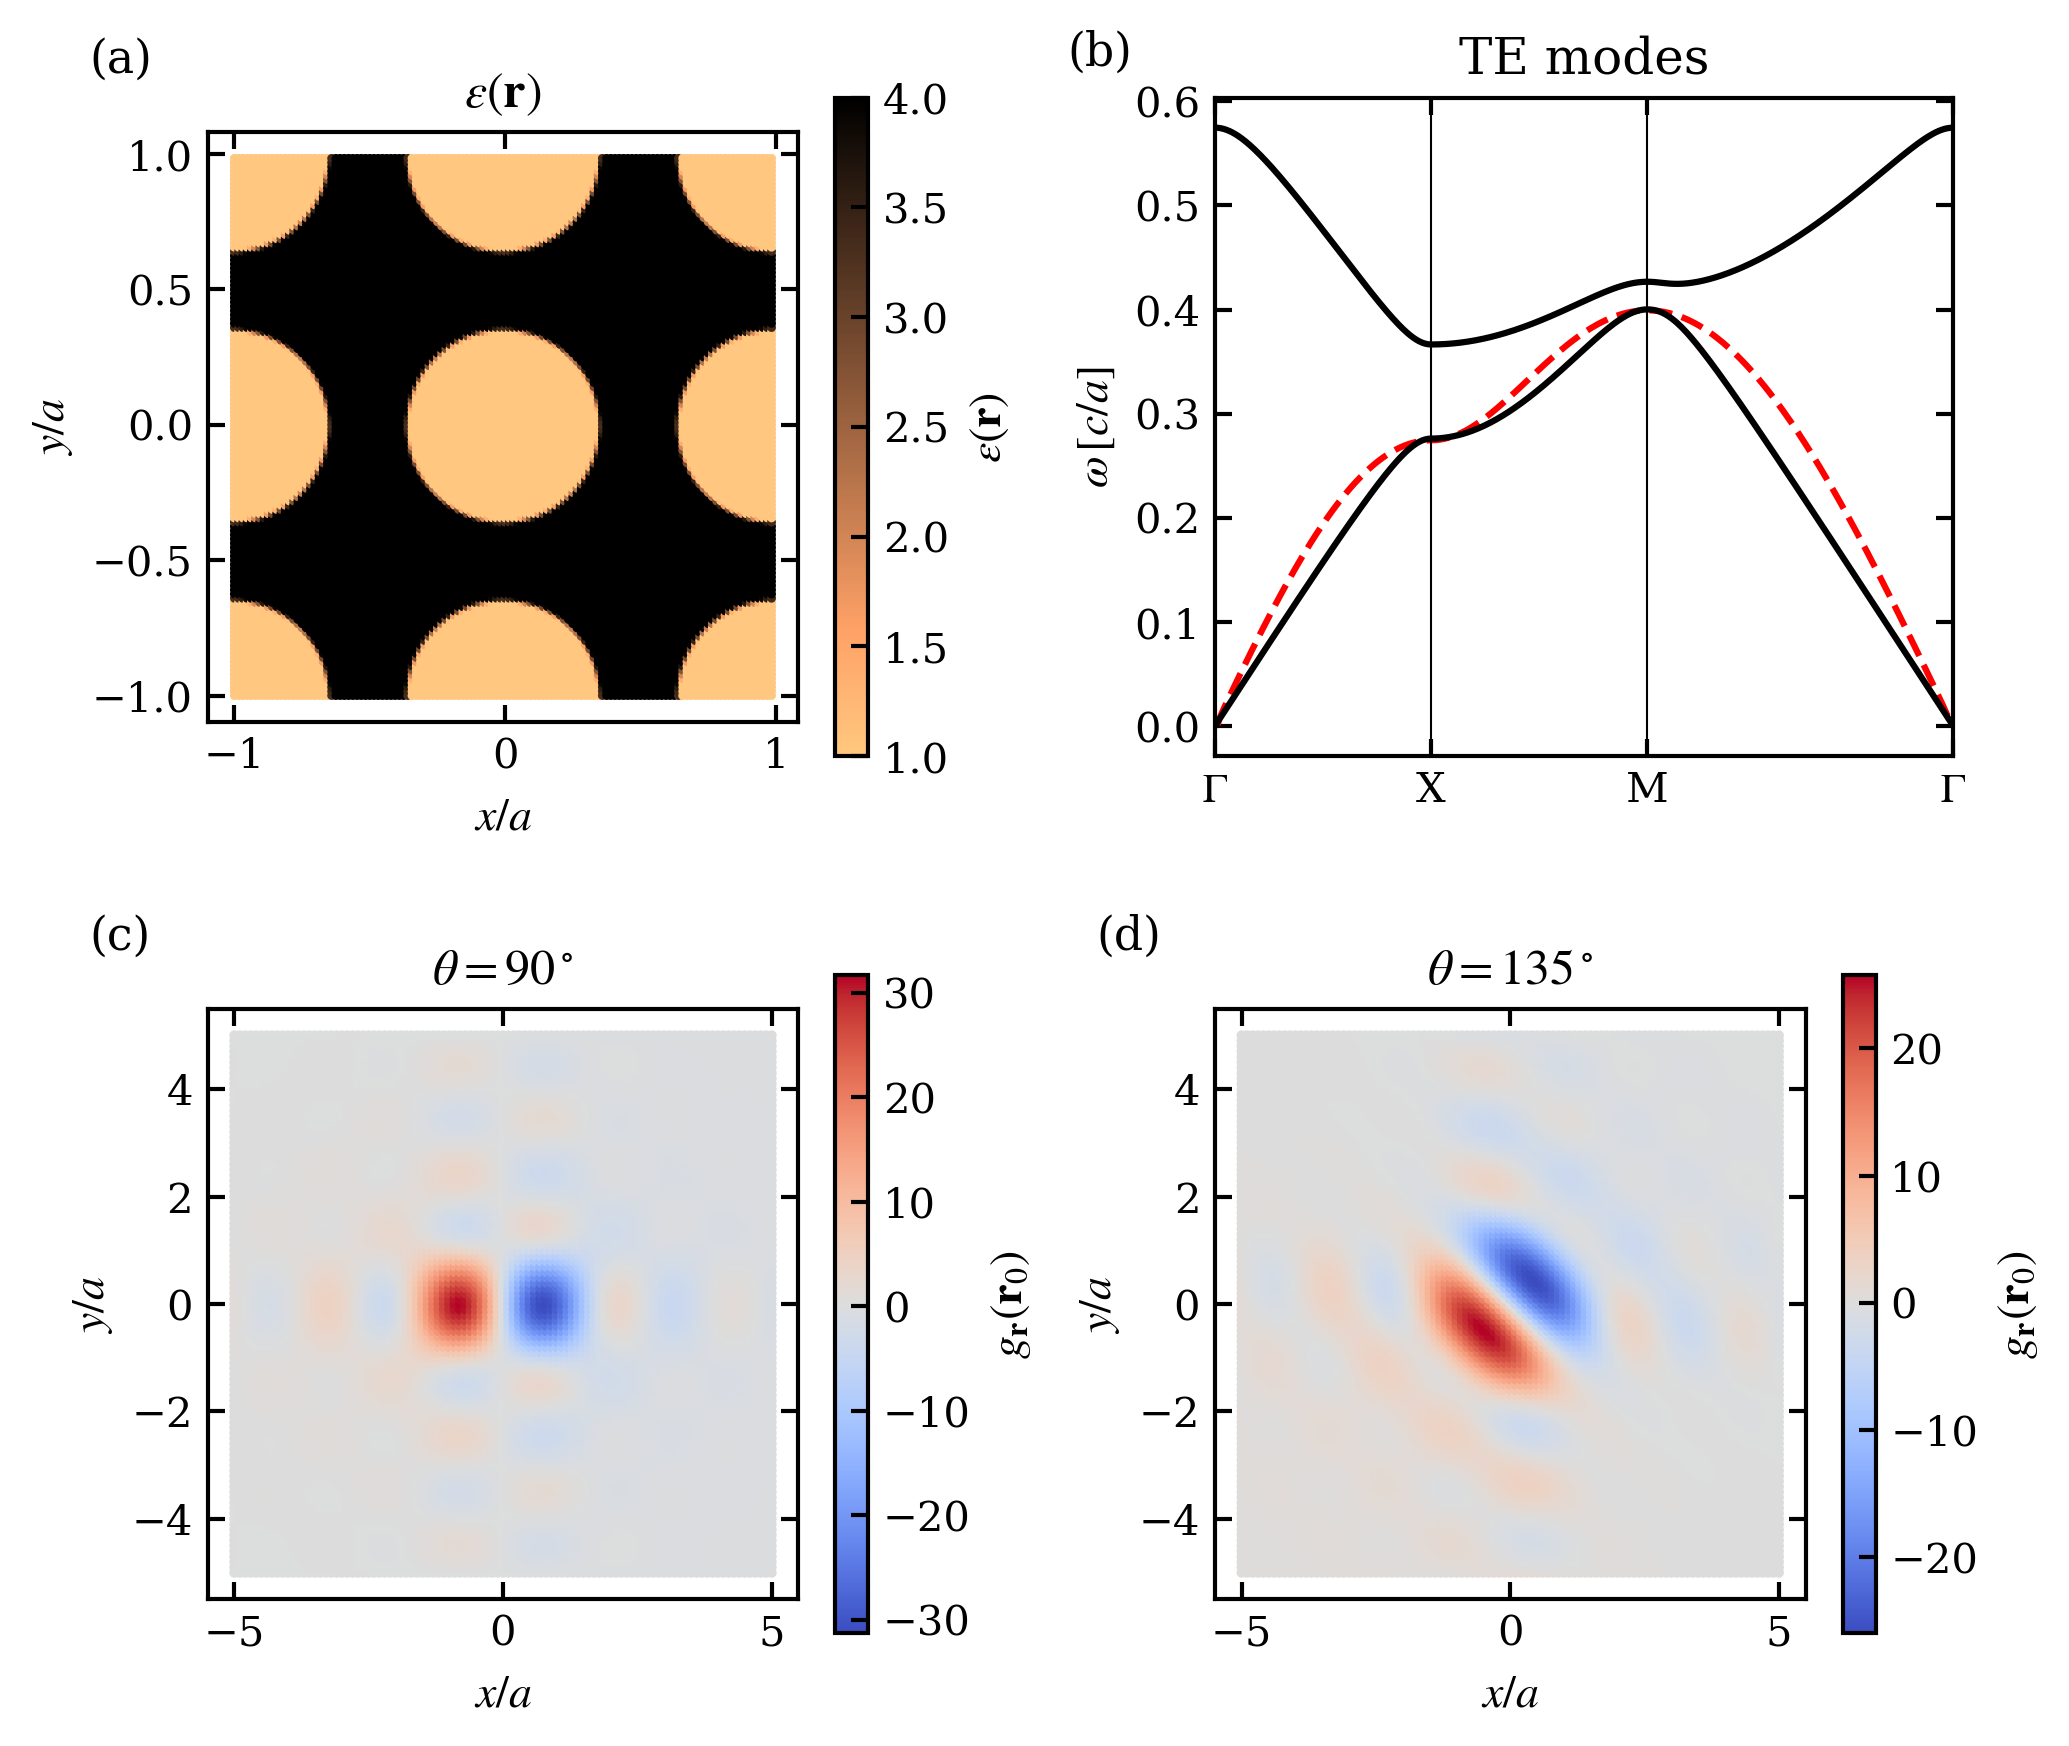

In [65]:
fig, axs = plt.subplots(2, 2)  # two-column width

panel_labels = ['(a)', '(b)', '(c)', '(d)']

# --- First quadrant: dielectric structure ---
ax = axs[0, 0]
sc1 = ax.scatter(x1, y1, c=z1, marker="o", cmap="copper_r", s=mf.marker_size(len(x1)))
fig.colorbar(sc1, ax=ax, label=r"$\epsilon(\mathbf{r})$")
ax.set_title(r"$\epsilon(\mathbf{r})$")
ax.set_xlabel(r"$x/a$")
ax.set_ylabel(r"$y/a$")
ax.set_aspect("equal")
ax.text(-0.2, 1.1, panel_labels[0], transform=ax.transAxes)

# --- Second quadrant: TE bands ---
ax = axs[0, 1]
for n in evals:
    ax.plot(k_dist, np.sqrt(n), color="r", linestyle="--")
ax.plot(k_dist, freqs, color="k")
ax.set_xlim(k_node[0], k_node[-1])
ax.set_xticks(k_node)
ax.set_xticklabels(K_LABEL)
for k in k_node:
    ax.axvline(x=k, linewidth=0.5, color="k")
ax.set_ylabel(r"$\omega \, [c/a]$")
ax.set_title("TE modes")
ax.text(-0.2, 1.05, panel_labels[1], transform=ax.transAxes)

# --- Third quadrant: g(r0,r) dipole 1 ---
ax = axs[1, 0]
emitter_indx = 0
sc2 = ax.scatter(
    rpts[:, 0],
    rpts[:, 1],
    c=gr0r_1[emitter_indx, :],
    s=mf.marker_size(len(rpts[:, 0])),
    marker="o",
    cmap="coolwarm",
)
fig.colorbar(sc2, ax=ax, label=r"$g_\mathbf{r}(\mathbf{r}_0)$")
ax.set_title(r"$\theta={:.0f}^\circ$".format(THETA_1*180/np.pi))
ax.set_xlabel(r"$x/a$")
ax.set_ylabel(r"$y/a$")
ax.set_aspect("equal")
ax.text(-0.2, 1.1, panel_labels[2], transform=ax.transAxes)

# --- Fourth quadrant: g(r0,r) dipole 2 ---
ax = axs[1, 1]
emitter_indx = 0
sc3 = ax.scatter(
    rpts[:, 0],
    rpts[:, 1],
    c=gr0r_2[emitter_indx, :],
    s=mf.marker_size(len(rpts[:, 0])),
    marker="o",
    cmap="coolwarm",
)
fig.colorbar(sc3, ax=ax, label=r"$g_\mathbf{r}(\mathbf{r}_0)$")
ax.set_title(r"$\theta={:.0f}^\circ$".format(THETA_2*180/np.pi))
ax.set_xlabel(r"$x/a$")
ax.set_ylabel(r"$y/a$")
ax.set_aspect("equal")
ax.text(-0.2, 1.1, panel_labels[3], transform=ax.transAxes)

# --- Layout and save ---
fig.tight_layout(pad=1.0)
fig.savefig("./figures/paper_figure_2.svg")
plt.show()

## Figure 3

In [29]:
alpha_norm = ALPHA/np.abs(J1)
j1_norm = J1/np.abs(J1)
j2_norm = J2/np.abs(J1)

infiniteModel = tb.tb_model(2, 2, LAT, ORB)

# onsite term
infiniteModel.set_onsite([alpha_norm])

# 1st nn
infiniteModel.set_hop(j1_norm, 0, 0, [1, 0])
infiniteModel.set_hop(j1_norm, 0, 0, [0, 1])

# 2nd nn
infiniteModel.set_hop(j2_norm, 0, 0, [1, 1])
infiniteModel.set_hop(j2_norm, 0, 0, [1, -1])

In [30]:
# --- Generate k-point grid in the 2D Brillouin zone ---
# Assuming square BZ [-0.5, 0.5) x [-0.5, 0.5) in reciprocal coords
kx = np.linspace(-0.5, 0.5, NK)
ky = np.linspace(-0.5, 0.5, NK)
kx_grid, ky_grid = np.meshgrid(kx, ky)

# --- Compute band energies ---
omega = np.zeros_like(kx_grid)
for i in range(NK):
    for j in range(NK):
        kvec = [kx_grid[i, j], ky_grid[i, j]]
        evals = infiniteModel.solve_one(kvec)  # PythTB band energies at k
        omega[i, j] = evals[BAND_INDEX]

In [31]:
# load the data from a file
data_fields = mf.load("./data/kimble/Nk64/MPB_output.pkl")
Ex = data["Ex"]
Ey = data["Ey"]
Ez = data["Ez"]
kpts = data["kpts"]

detuning_freq = mf.load("./data/kimble/detuning_freq.pkl")

# .. Select the dipole moment
dipole_moment_1 = np.array([np.cos(THETA_1), np.sin(THETA_1), 0])
dipole_moment_2 = np.array([np.cos(THETA_2), np.sin(THETA_2), 0])

# .. Define the fields of the selected band
E_band = [Ex[BAND_INDEX, :, :], Ey[BAND_INDEX, :, :], Ez[BAND_INDEX, :, :]]

# %% Finite model definition

# Cut the system
temporalModel = infiniteModel.cut_piece(
    N_CELLS, fin_dir=0, glue_edgs=False
)  # cutout along 1st direction
finiteModel = temporalModel.cut_piece(
    N_CELLS, fin_dir=1, glue_edgs=False
)  # cutout along 2nd direction

# Let me recalculate the coupling accordingly with the system's size.
# NOTE: the indexing is now "xy" so that the ordering of rjpts coincides with the one created by pythonTB

if N_CELLS % 2 == 0:
    xjg = np.arange(-N_CELLS/2, N_CELLS/2, 1)
    yjg = np.arange(-N_CELLS/2, N_CELLS/2 + 1, 1)
else:
    xjg = np.arange(-(N_CELLS//2), N_CELLS//2 + 1, 1)
    yjg = np.arange(-(N_CELLS//2), N_CELLS//2 + 1, 1)
rjpts = mf.meshgrid_points(xjg, yjg, indexing="xy")

gr0rj_1 = mf.compute_gr0r(E_band, dipole_moment_1, detuning_freq, kpts, rjpts)
gr0rj_1_norm = gr0rj_1 * np.abs(J1)  # normalize to |t1|
gr0rj_2 = mf.compute_gr0r(E_band, dipole_moment_2, detuning_freq, kpts, rjpts)
gr0rj_2_norm = gr0rj_2 * np.abs(J1)  # normalize to |t1|
# TODO: check normalization here, does it make sense?

# %% Build the light-matter Hamiltonian

# ... non-local couplings
values_1 = gr0rj_1_norm[BAND_INDEX, :]
values_2 = gr0rj_2_norm[BAND_INDEX, :]

# small check before proceeding
assert len(values_1) == len(values_2), "Unexpected different lengths for the couplings!"

indexes = np.arange(0, len(gr0rj_1[0, :]), 1)
couplings_1 = [[list(values_1), list(indexes)]]
couplings_2 = [[list(values_2), list(indexes)]]

# build the light-matter Hamiltonian
H_total_1 = mf.make_light_matter_Hamiltonian(finiteModel, detuning_freq, couplings_1)
H_total_2 = mf.make_light_matter_Hamiltonian(finiteModel, detuning_freq, couplings_2)

# %% Compute time evolution

from scipy.sparse.linalg import expm_multiply

tvals = np.linspace(T0, TF, T_STEPS)

# Define initial condition
assert np.shape(H_total_1) == np.shape(H_total_2), "Unexpected different shapes for the Hamiltonians!"
psi0 = np.zeros(np.shape(H_total_1)[0])
psi0[0] = 1

# Compute time evolution
psit_1 = expm_multiply(-1j * H_total_1, psi0, T0, TF, T_STEPS, endpoint=True)
psit_2 = expm_multiply(-1j * H_total_2, psi0, T0, TF, T_STEPS, endpoint=True)

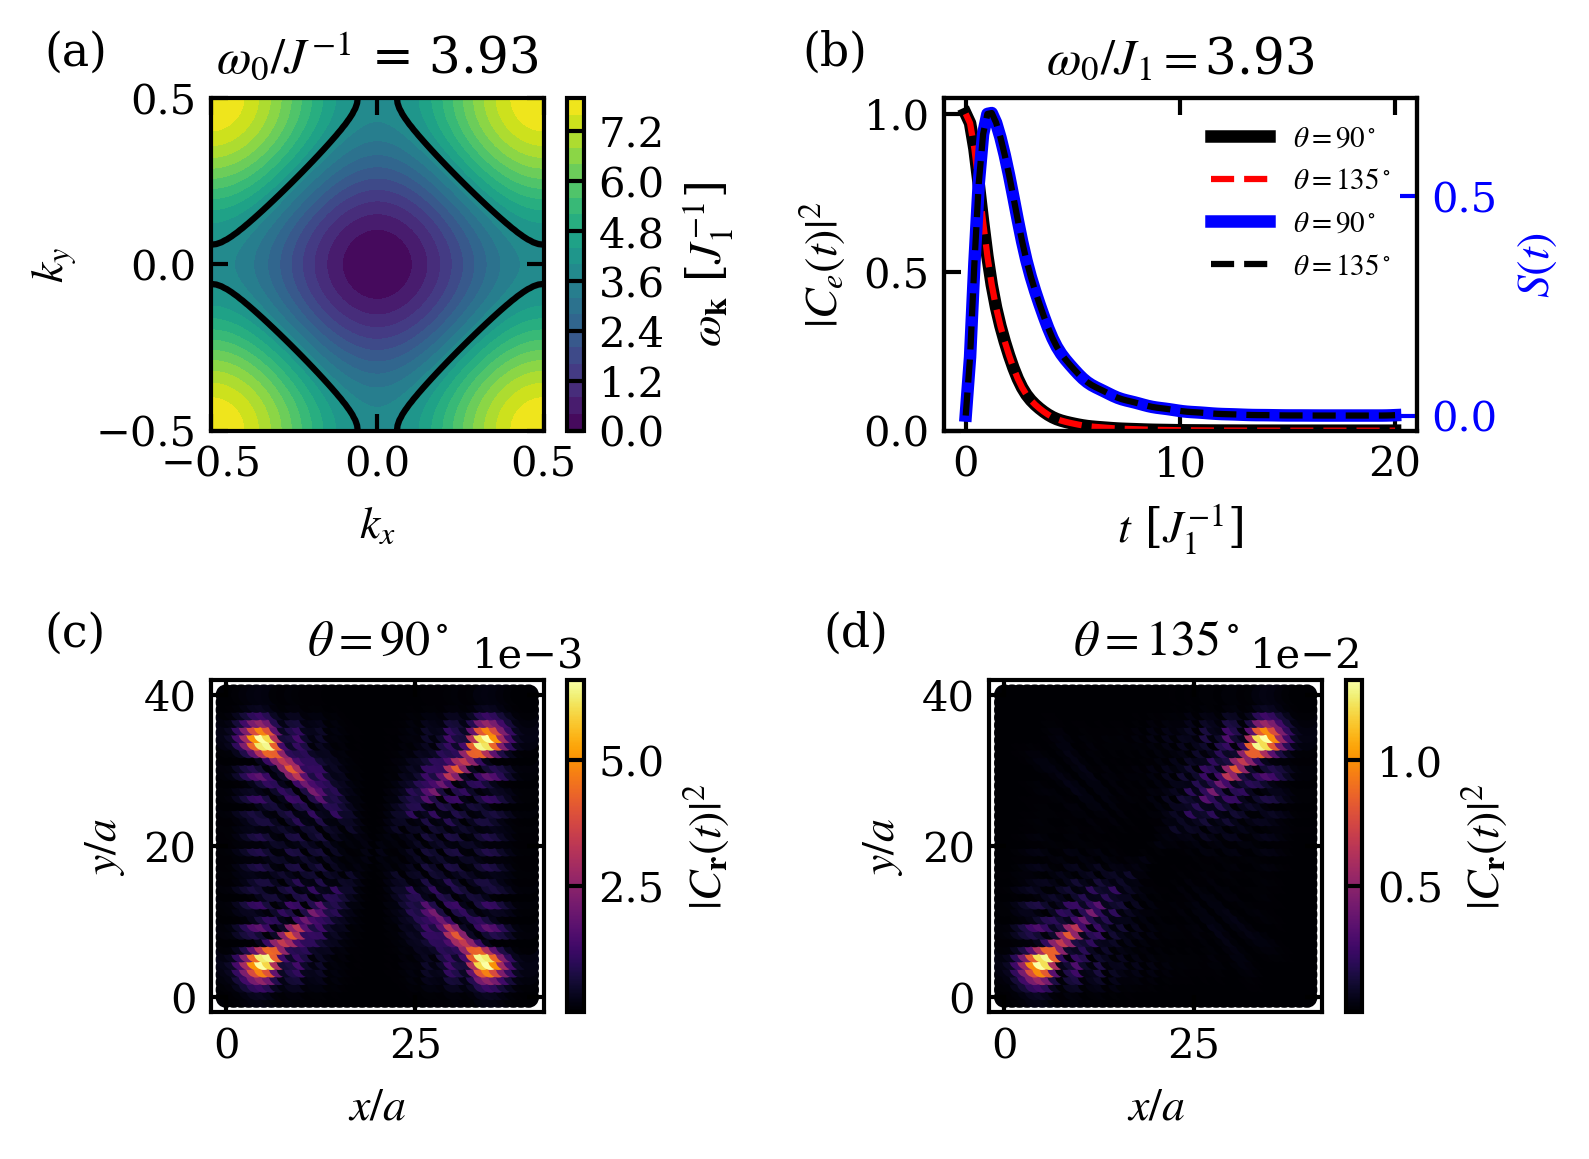

In [68]:
# --- Plotting ---
fig, axs = plt.subplots(2, 2, figsize=(5.5, 4))

panel_labels = ['(a)', '(b)', '(c)', '(d)']

# Filled contour of band dispersion in the first quadrant
ax = axs[0,0]
c = ax.contourf(kx_grid, ky_grid, omega, levels=20, cmap="viridis")
fig.colorbar(c, ax=ax, label=r"$\omega_\mathbf{k}$ [$J_1^{-1}$]")

# Isofrequency contour at the emitter frequency
ax.contour(kx_grid, ky_grid, omega, levels=[detuning_freq], colors="black", linewidths=1.5)

ax.set_xlabel(r"$k_x$")
ax.set_ylabel(r"$k_y$")
ax.set_title(r"$\omega_0/J^{-1}$ = " + f"%.2f" % detuning_freq)
ax.set_aspect("equal")
ax.text(-0.5, 1.1, panel_labels[0], transform=ax.transAxes)

# %% Plot emitter's dynamics

# Prepare data to be plotted ...

# get emitter component of the overall wavefunction
mod_Ce_squared_1 = np.abs(psit_1[:, 0]) ** 2
mod_Ce_squared_2 = np.abs(psit_2[:, 0]) ** 2

# compute the entanglement for both cases
entropy_1 = mf.binary_entropy(mod_Ce_squared_1)
entropy_2 = mf.binary_entropy(mod_Ce_squared_2)

# --- plotting ---
ax1 = axs[0,1]

# left y-axis: population
l1, = ax1.plot(tvals, mod_Ce_squared_1, lw=3, c="k", label=r"$\theta=90^\circ$")
l2, = ax1.plot(tvals, mod_Ce_squared_2, c="r", ls="--", label=r"$\theta=135^\circ$")
ax1.set_xlabel(r"$t$ [$J_1^{-1}$]")
ax1.set_ylabel(r"$|C_e(t)|^2$")
ax1.set_ylim([0, 1.05])

# right y-axis: entropy
ax2 = ax1.twinx()
l3, = ax2.plot(tvals, entropy_1, c="b", lw=3, label=r"$\theta=90^\circ$")
l4, = ax2.plot(tvals, entropy_2, c="k", ls="--", label=r"$\theta=135^\circ$")
ax2.set_ylabel(r"$S(t)$", color="b")
ax2.tick_params(axis="y", colors="b")

# combine legends
lines = [l1, l2, l3, l4]
labels = [line.get_label() for line in lines]
ax1.legend(lines, labels, loc="best", fontsize=7)

# title
ax1.set_title(r"$\omega_0/J_1 = $" + f"%.2f" % detuning_freq)
ax1.text(-0.3, 1.1, panel_labels[1], transform=ax1.transAxes)

# get positions in Cartesian coordinates (requires find_positions() defined above)
positions = mf.find_positions(finiteModel._orb, finiteModel._lat)

# get photonic component of the overall wave function at selected time, i.e, tvals[time_index]
mod_Cr_squared_1 = np.abs(psit_1[TIME_INDEX, 1 : np.shape(psit_1)[1]]) ** 2
mod_Cr_squared_2 = np.abs(psit_2[TIME_INDEX, 1 : np.shape(psit_2)[1]]) ** 2

x = positions[:, 0]
y = positions[:, 1]
z1 = mod_Cr_squared_1
z2 = mod_Cr_squared_2

# Plot figure ...
ax = axs[1,0]

# scatter plot
sc = ax.scatter(x, y, c=z1, s=mf.marker_size(len(x)), marker="o", cmap="inferno")

# axis properties
ax.set(xlabel=r"$x/a$", ylabel=r"$y/a$", title=r"$\theta=90^\circ$")
ax.set_aspect("equal")
ax.text(-0.5, 1.1, panel_labels[2], transform=ax.transAxes)

# colorbar
cbar = fig.colorbar(sc, ax=ax)
cbar.formatter.set_powerlimits((0, 0))
cbar.set_label(r"$|C_\mathbf{r}(t)|^2$")

# Plot figure ...
ax = axs[1,1]

# scatter plot
sc = ax.scatter(x, y, c=z2, s=mf.marker_size(len(x)), marker="o", cmap="inferno")

# axis properties
ax.set(xlabel=r"$x/a$", ylabel=r"$y/a$", title=r"$\theta=135^\circ$")
ax.set_aspect("equal")
ax.text(-0.5, 1.1, panel_labels[3], transform=ax.transAxes)

# colorbar
cbar = plt.colorbar(sc, ax=ax)
cbar.formatter.set_powerlimits((0, 0))
cbar.set_label(r"$|C_\mathbf{r}(t)|^2$")

fig.tight_layout(pad=1.0)
fig.savefig("./figures/paper_figure_3.svg")